## Activating a GPU Runtime

To activate a GPU runtime in Google Colab, follow these steps:

1.  Go to the menu bar at the top of the page.
2.  Click on `Runtime`.
3.  Select `Change runtime type`.
4.  In the `Hardware accelerator` dropdown menu, choose `GPU`.
5.  Click `Save`.

Colab will then restart your runtime with GPU acceleration enabled, which can significantly speed up training for deep learning models.

# Land-cover segmentation on OpenEarthMap with PyTorch Lightning

**Goal.** Train a network that assigns each pixel of an aerial/satellite image to one of the 9 OpenEarthMap land-cover classes, and evaluate it with the multi-class IoU (Jaccard index).

**What this notebook contains**

1. Dataset download and an **exploratory analysis** (class frequencies, regions, image sizes) that motivates the design choices.
2. The required components, with the reasoning behind each choice: `OEMDataset`, `OEMDataModule`, the model, `OEMSegmentationModule`, and the training/evaluation code.
3. A **baseline** that follows the TODO specification, and an **ablation study** that adds one improvement at a time: data augmentation, a class-weighted CE + Dice loss, a tuned learning-rate schedule with a longer training, and a larger encoder.
4. **Analysis of the results**: learning curves, a comparison table, per-class IoU, a confusion matrix, qualitative predictions, and conclusions and limitations.

**Key results** (test set, whole images, best checkpoint by validation mIoU):

| Run | Configuration | Test mIoU (9 classes) | Test mIoU (8 classes, no Background) |
|---|---|---|---|
| E0 | Baseline as specified in the TODOs (SegFormer `mit_b0`, CE, constant lr 1e-4) | 0.628 | 0.588 |
| E3 | + augmentation, weighted CE + Dice, lr 5e-4 with warm-up + cosine, 2.4× longer training | 0.660 | 0.622 |
| **E4** | **E3 with the larger `mit_b2` encoder** | **0.688** | **0.653** |

- **The largest gains come from training long enough with a suitable learning-rate schedule (+0.032) and from model capacity (+0.027).** At the baseline budget of ~1,450 steps the model is still under-fitting: augmentation and the weighted CE + Dice loss change the test mIoU by less than ±0.011, within the run-to-run noise of a single seed.
- **Validation and test agree within 0.012 mIoU in every run**, which confirms that the random 80/20 split of `train.txt` is a reliable model-selection proxy.
- **The remaining errors are mostly between visually similar classes**: Bareland is confused with Developed space, Road with Developed space, and Rangeland with Tree.

## Where each TODO of the template is solved

All TODOs of the original template are solved inside the cells where they appeared, and every section of the template keeps its title and position. The table maps each TODO to its implementation; the extra work (analysis, ablation study, results) is added around these sections.

| Template TODO | Where it is solved | Notes |
|---|---|---|
| **Dataset**: read `train.txt` / `test.txt` (`utf-8-sig`), build `<region>/images/<name>` and `<region>/labels/<name>`, store the transform | *Dataset* → `OEMDataset.__init__` | Region = prefix before the last `_` |
| **Dataset**: return the number of pairs | `OEMDataset.__len__` | |
| **Dataset**: `(C, H, W)` → `(H, W, C)`, apply `self.transform(image=..., mask=...)` or convert manually, return `float (3, H, W)` and `long (H, W)` | `OEMDataset.__getitem__` | Keeps the 3 RGB bands |
| **DataModule**: store the hyperparameters, define `train_transform` (pad, random crop, ImageNet normalization, `ToTensorV2`) and the deterministic `val_transform` | *DataModule* → `OEMDataModule.__init__` | Same signature as the template, plus optional arguments with defaults (`augment`, `train_repeats`, …). The deterministic transform evaluates the **whole image** (padded to 1024, padding ignored) instead of a crop; the reason is explained in the DataModule section |
| **DataModule**: `setup` for `fit` and `test`, deciding where the validation samples come from | `OEMDataModule.setup` | Random 20% hold-out of `train.txt` (seed 42), motivated by the exploratory analysis; the test split comes from `test.txt` with the validation transform |
| **DataModule**: train / val / test `DataLoader`s | `train_dataloader`, `val_dataloader`, `test_dataloader` | Shuffled training loader (a `RandomSampler` when `train_repeats > 1`); validation and test are not shuffled |
| **Model**: network mapping `(B, 3, H, W)` to `(B, 9, H, W)` logits | *Model* → `build_model` | SegFormer from `segmentation_models_pytorch`, the 113_B option |
| **LightningModule**: store the model and lr, define the 9-class loss and the IoU metrics | *LightningModule* → `OEMSegmentationModule.__init__` | Cross-entropy (optional class-weighted CE + Dice); `JaccardIndex(task="multiclass", num_classes=9)` for validation and test |
| **LightningModule**: `forward` | `OEMSegmentationModule.forward` | |
| **LightningModule**: `training_step` logging `train_loss` | `OEMSegmentationModule.training_step` | |
| **LightningModule**: `validation_step` updating the IoU, logging `val_loss` and `val_iou` | `OEMSegmentationModule.validation_step` | |
| **LightningModule**: `test_step` logging `test_loss` and `test_iou` | `OEMSegmentationModule.test_step` | Also accumulates a confusion matrix |
| **LightningModule**: optimizer (e.g. AdamW) | `OEMSegmentationModule.configure_optimizers` | AdamW; optional warm-up + cosine schedule |
| **Training**: `ModelCheckpoint` and `EarlyStopping` on a validation metric | *Training and evaluation* → `run_experiment` (in *Training utilities*) | Both monitor `val_iou` (the template's example was `val_loss`; the reason is explained in the LightningModule section) |
| **Training**: `TensorBoardLogger` under `logs/` | `run_experiment` | One run per experiment |
| **Training**: `Trainer` (accelerator, devices, precision, max_epochs, callbacks, logger) | `run_experiment` | GPU, `16-mixed` |
| **Training**: build the model and pass it to `OEMSegmentationModule(model=..., lr=...)`; instantiate `OEMDataModule` | `run_experiment` | |
| **Training**: `trainer.fit(model, datamodule=dm)` and `trainer.test(model, datamodule=dm)` | `run_experiment`, executed for the baseline in *E0: Baseline* | The test uses the best checkpoint (`ckpt_path="best"`) |

**Changes to the template's own code.**
- The **setup cell** no longer stops outside Colab: it detects the environment and behaves exactly as before on Colab (data under `/content`), or uses `./data` locally.
- The `!pip install` cells run only on Colab.
- The cell that **visualizes a random sample** is unchanged, except that it takes `DATA_ROOT` from the setup cell instead of redefining it as `/content`.

In [1]:
# Setup: download and extract the OpenEarthMap dataset from the Hugging Face Hub.
# Designed for Google Colab (data under /content). It also runs outside Colab (data under ./data),
# which is how the experiments in this notebook were executed (see "Execution environment" below).
import os
import zipfile
from huggingface_hub import hf_hub_download

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

HF_REPO_ID = "lorenzoinnocenti/oem-masterai-project"
PROJECT_DIR = "/content" if IN_COLAB else os.getcwd()
DATA_ROOT = "/content" if IN_COLAB else os.path.join(PROJECT_DIR, "data")
ARCHIVE_PATH = os.path.join(DATA_ROOT, "OpenEarthMap.zip")
OEM_ROOT = os.path.join(DATA_ROOT, "OpenEarthMap")
os.makedirs(DATA_ROOT, exist_ok=True)

# 1. Download the OpenEarthMap archive (a single file, skipped if already present)
print(f"Downloading OpenEarthMap.zip from https://huggingface.co/datasets/{HF_REPO_ID} ...")
hf_hub_download(
    repo_id=HF_REPO_ID,
    repo_type="dataset",
    filename="OpenEarthMap.zip",
    local_dir=DATA_ROOT,
)

# 2. Extract archive if not already extracted
if not os.path.isdir(OEM_ROOT):
    print("Extracting the dataset archive...")
    try:
        with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
            archive.extractall(OEM_ROOT)
    except zipfile.BadZipFile as e:
        # If extraction fails due to a corrupted file, delete it so the user can re-download
        if os.path.exists(ARCHIVE_PATH):
            os.remove(ARCHIVE_PATH)
        raise RuntimeError(
            "The downloaded archive was corrupted or invalid and has been removed. Please run this cell again to re-download."
        ) from e

print(f"Dataset ready under {OEM_ROOT}")

Dataset ready under /home/antonio/projects/Applicazioni_AI /data/OpenEarthMap


# Understanding the OpenEarthMap (OEM) Dataset

**OpenEarthMap** is a high-resolution benchmark dataset designed for land cover mapping and semantic segmentation across diverse geographic regions worldwide. It features high-resolution aerial and satellite imagery spanning dozens of cities and countries across multiple continents.

---

## Dataset Structure & Layout

Once downloaded, the dataset is organized under `/content/OpenEarthMap/` (on Colab; `./data/OpenEarthMap/` when running locally) with the following hierarchy:

```
/content/OpenEarthMap/
├── train.txt               # Plain-text list of training sample filenames (e.g., tokyo_1.tif)
├── test.txt                # Plain-text list of test/validation sample filenames
├── readme.txt              # Dataset overview and notes
└── <region-folder>/        # Region-specific directory (e.g., tokyo, aachen, austin, ...)
    ├── images/             # RGB satellite/aerial images in TIFF format
    │   ├── <region>_1.tif
    │   ├── <region>_2.tif
    │   └── ...
    └── labels/             # Semantic segmentation masks in TIFF format
        ├── <region>_1.tif
        ├── <region>_2.tif
        └── ...
```

Each sample image in `images/` shares the exact same filename and dimensions as its corresponding ground-truth mask in `labels/`. For example, `tokyo_1.tif` in `tokyo/images/` pairs directly with `tokyo_1.tif` in `tokyo/labels/`.

---

## Content & Semantic Classes

The ground-truth label masks are single-channel raster TIFF images where each pixel contains an integer value (`0` through `8`) indicating its land cover category:

| Class ID | Class Name | Description |
| :---: | :--- | :--- |
| **0** | **Background** | Unlabeled, nodata, or undefined areas |
| **1** | **Bareland** | Exposed soil, sand, rocks, and non-vegetated terrain |
| **2** | **Rangeland** | Grasslands, scrublands, and natural pastures |
| **3** | **Developed space** | Impervious surfaces, open paved areas, sports facilities |
| **4** | **Road** | Highways, streets, paved paths, and transit networks |
| **5** | **Tree** | Forest canopy, dense woods, and individual tree clusters |
| **6** | **Water** | Rivers, lakes, oceans, canals, and reservoirs |
| **7** | **Agriculture land** | Croplands, cultivated fields, and orchards |
| **8** | **Building** | Residential, commercial, and industrial structures |

---

## Splits & Setup

- **`train.txt`** & **`test.txt`**: Contain the file listings for the respective dataset splits. The region name is derived from the prefix preceding the trailing underscore (e.g., `tokyo_1.tif` belongs to the `tokyo` region).
- **Google Colab Environment**: The setup cell downloads the dataset from the [Hugging Face Hub](https://huggingface.co/datasets/lorenzoinnocenti/oem-masterai-project) directly into Colab's local `/content/OpenEarthMap` directory to ensure high I/O throughput during training.

In [2]:
# Keep the working directory stable; the dataset uses the absolute DATA_ROOT path.
os.chdir(PROJECT_DIR)

In [3]:
# Colab: install matplotlib as in the original notebook. Locally every package comes from the
# uv environment (pyproject.toml), so nothing is installed here.
if IN_COLAB:
    get_ipython().system("pip install -q matplotlib")
else:
    # Make the environment's executables (e.g. tensorboard, used by %tensorboard below) visible to the kernel
    import sys
    os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ.get("PATH", "")

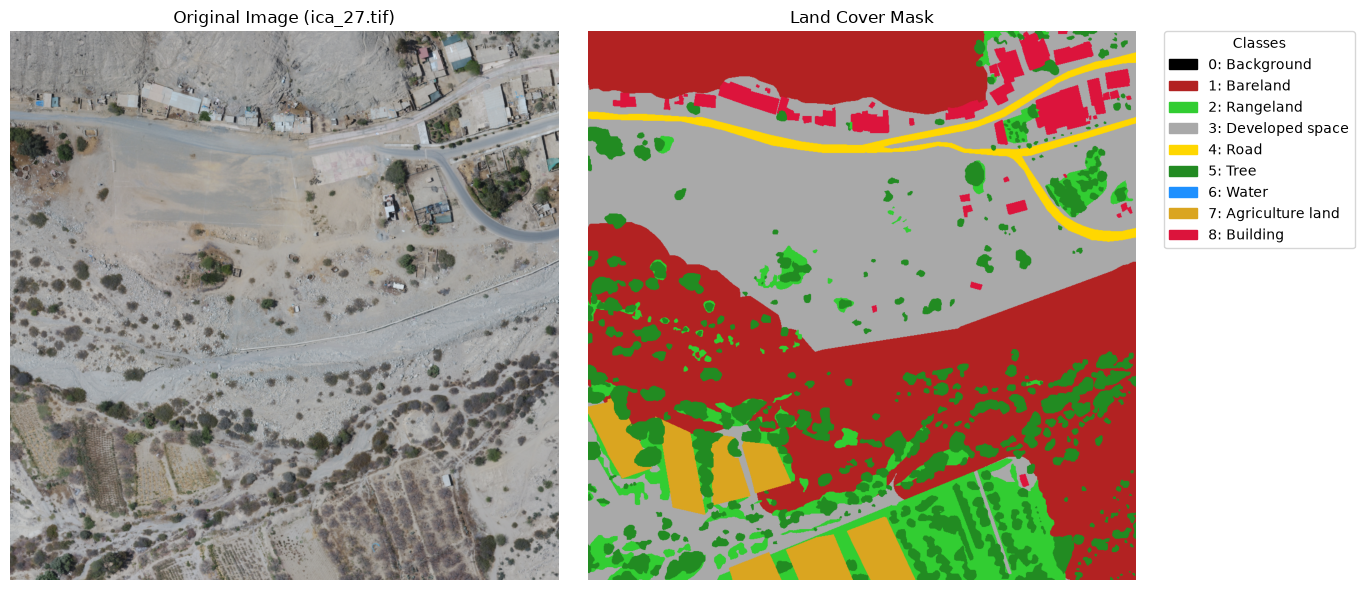

In [4]:
import os
import random
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

OEM_ROOT = os.path.join(DATA_ROOT, "OpenEarthMap")

# Hardcoded colors and names for OpenEarthMap integer labels (0-8)
CLASS_INFO = {
    0: {"name": "Background", "color": [0, 0, 0]},            # Black
    1: {"name": "Bareland", "color": [178, 34, 34]},          # Firebrick
    2: {"name": "Rangeland", "color": [50, 205, 50]},         # Lime Green
    3: {"name": "Developed space", "color": [169, 169, 169]}, # Gray
    4: {"name": "Road", "color": [255, 215, 0]},              # Gold
    5: {"name": "Tree", "color": [34, 139, 34]},              # Forest Green
    6: {"name": "Water", "color": [30, 144, 255]},            # Dodger Blue
    7: {"name": "Agriculture land", "color": [218, 165, 32]}, # Goldenrod
    8: {"name": "Building", "color": [220, 20, 60]},          # Crimson
}

# 1. Pick a random sample from train.txt (or directory search as fallback)
train_txt_path = os.path.join(OEM_ROOT, "train.txt")
if os.path.exists(train_txt_path):
    with open(train_txt_path, "r", encoding="utf-8-sig") as f:
        samples = [line.strip() for line in f if line.strip()]
    random_name = random.choice(samples)
    region = random_name.rsplit("_", 1)[0]
    img_path = os.path.join(OEM_ROOT, region, "images", random_name)
    lbl_path = os.path.join(OEM_ROOT, region, "labels", random_name)
else:
    all_images = glob.glob(os.path.join(OEM_ROOT, "*", "images", "*.tif"))
    img_path = random.choice(all_images)
    lbl_path = img_path.replace("/images/", "/labels/")
    random_name = os.path.basename(img_path)

# 2. Load the original image and integer label
img = Image.open(img_path).convert("RGB")
label = np.array(Image.open(lbl_path))

# 3. Render the integer label into an RGB color mask
color_mask = np.zeros((*label.shape, 3), dtype=np.uint8)
for class_id, info in CLASS_INFO.items():
    color_mask[label == class_id] = info["color"]

# 4. Plot the image and colored mask with legend
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img)
axes[0].set_title(f"Original Image ({random_name})")
axes[0].axis("off")

axes[1].imshow(color_mask)
axes[1].set_title("Land Cover Mask")
axes[1].axis("off")

# Create legend handles for each class
legend_patches = [
    mpatches.Patch(color=np.array(info["color"]) / 255.0, label=f"{cid}: {info['name']}")
    for cid, info in CLASS_INFO.items()
]
axes[1].legend(
    handles=legend_patches,
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    borderaxespad=0.0,
    title="Classes",
)

plt.tight_layout()
plt.show()

## Exploratory data analysis

Before designing the pipeline, we measure four properties of the data that drive the design choices:

- **Class frequencies** (share of labelled pixels per class): they decide whether the loss needs class weighting.
- **Regions** shared between `train.txt` and `test.txt`: they decide how the validation set should be built.
- **Image sizes**: they decide the crop and padding strategy.
- **How many images contain each class**: a class that appears in few images is hard to learn.

train: 2303 images from 75 regions
test : 384 images from 75 regions
regions in test but not in train: []
most common sizes (H, W): [((1024, 1024), 1924), ((1000, 1000), 497), ((650, 650), 182), ((900, 900), 35)]
smallest side: 406 px, largest side: 1024 px

class              train px %  test px %  train imgs  weight
0: Background            0.70       0.84    653/2303   2.629
1: Bareland              1.83       1.28    360/2303   1.629
2: Rangeland            20.89      20.88   2249/2303   0.482
3: Developed space      18.59      19.64   2234/2303   0.511
4: Road                  6.69       7.00   2162/2303   0.852
5: Tree                 18.35      18.63   2273/2303   0.515
6: Water                 3.21       2.34   1240/2303   1.229
7: Agriculture land      12.65      11.73   1007/2303   0.620
8: Building             17.08      17.66   2229/2303   0.533


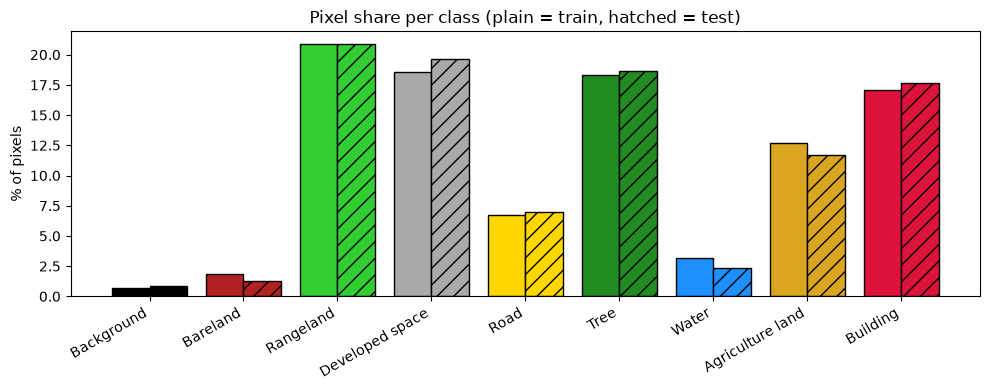

In [5]:
import collections
from concurrent.futures import ThreadPoolExecutor

CLASS_NAMES = [CLASS_INFO[k]["name"] for k in range(9)]
CLASS_COLORS = np.array([CLASS_INFO[k]["color"] for k in range(9)], dtype=np.uint8)


def read_split_names(split):
    with open(os.path.join(OEM_ROOT, f"{split}.txt"), "r", encoding="utf-8-sig") as f:
        return [line.strip() for line in f if line.strip()]


def label_stats(name):
    region = name.rsplit("_", 1)[0]
    label = np.array(Image.open(os.path.join(OEM_ROOT, region, "labels", name)))
    return np.bincount(label.ravel(), minlength=9)[:9], label.shape


split_names = {split: read_split_names(split) for split in ("train", "test")}
pixel_counts, image_sizes, images_with_class = {}, {}, {}
for split, names in split_names.items():
    with ThreadPoolExecutor(max_workers=8) as ex:
        stats = list(ex.map(label_stats, names))
    pixel_counts[split] = np.sum([counts for counts, _ in stats], axis=0)
    images_with_class[split] = np.sum([counts > 0 for counts, _ in stats], axis=0)
    image_sizes[split] = collections.Counter(shape for _, shape in stats)

regions = {split: {n.rsplit("_", 1)[0] for n in names} for split, names in split_names.items()}
for split in ("train", "test"):
    print(f"{split:5s}: {len(split_names[split])} images from {len(regions[split])} regions")
print(f"regions in test but not in train: {sorted(regions['test'] - regions['train'])}")
all_sizes = image_sizes["train"] + image_sizes["test"]
print(f"most common sizes (H, W): {all_sizes.most_common(4)}")
print(f"smallest side: {min(min(s) for s in all_sizes)} px, largest side: {max(max(s) for s in all_sizes)} px")

freq = {split: counts / counts.sum() for split, counts in pixel_counts.items()}

# Class weights for the weighted loss used in the improved runs: inverse square root of the
# training pixel frequency, normalized to mean 1. Plain inverse frequency would give the rarest
# class a weight ~30x larger than the most common one, which makes training unstable;
# the square root keeps the ratio around 5x.
CLASS_WEIGHTS = 1.0 / np.sqrt(freq["train"])
CLASS_WEIGHTS = (CLASS_WEIGHTS / CLASS_WEIGHTS.mean()).round(3).tolist()

print(f"\n{'class':18s} {'train px %':>10s} {'test px %':>10s} {'train imgs':>11s} {'weight':>7s}")
for k in range(9):
    print(f"{k}: {CLASS_NAMES[k]:15s} {100 * freq['train'][k]:10.2f} {100 * freq['test'][k]:10.2f} "
          f"{images_with_class['train'][k]:6d}/{len(split_names['train'])} {CLASS_WEIGHTS[k]:7.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(9)
ax.bar(x - 0.2, 100 * freq["train"], width=0.4, label="train", color=CLASS_COLORS / 255.0, edgecolor="black")
ax.bar(x + 0.2, 100 * freq["test"], width=0.4, label="test", color=CLASS_COLORS / 255.0, edgecolor="black", hatch="//")
ax.set_xticks(x, CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("% of pixels")
ax.set_title("Pixel share per class (plain = train, hatched = test)")
plt.tight_layout()
plt.show()

**What the analysis shows and how it shapes the pipeline**

- **Same 75 regions in train and test.** The test set measures performance on *new images from known regions*, not on unseen cities. A validation set drawn at random from `train.txt` therefore matches the test distribution. A region-wise split would answer a different question (generalization to new cities), so we use a random 80/20 split of `train.txt` and keep `test.txt` untouched for the final evaluation.
- **Strong class imbalance.** Background (unlabelled areas, 0.7% of the pixels), Bareland (1.8%) and Water (3.2%) are rare, while Rangeland, Developed space, Tree and Building each cover 17–21% of the pixels. With a plain cross-entropy, rare classes contribute little to the gradient, and the macro-averaged IoU weights every class equally. This motivates a **class-weighted loss** and the **Dice loss**, which optimizes overlap per class.
- **Image sizes vary** (mostly 1024×1024 and 1000×1000, down to 406 px), always within 1024 px. Training uses random 224×224 crops (no padding needed, since the smallest side is 406 px). Evaluation runs on **whole images padded to 1024×1024**: padded pixels get a special label (`255`) that the loss and the metrics ignore, so the score covers every real pixel exactly once.
- **Background** is part of the required 9-class metric, so we train and evaluate on all 9 classes. Because it marks *unlabelled* areas rather than a land-cover type, we also report the mean IoU over the 8 land-cover classes, the convention of the OpenEarthMap benchmark.

In [6]:
# Colab: install the training libraries as in the original notebook (already in the uv environment locally).
if IN_COLAB:
    get_ipython().system("pip install -q pytorch-lightning torchmetrics segmentation_models_pytorch albumentations rasterio")

# Silence a few harmless, repetitive library messages so the training logs stay readable.
import logging
import warnings

warnings.filterwarnings("ignore", message=".*LeafSpec.*")
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*Precision 16-mixed is not supported by the model summary.*")
logging.getLogger("pytorch_lightning.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)

## Dataset

`OEMDataset` reads the file list of a split (`train.txt` / `test.txt`) and builds the image and label paths from the region prefix of each filename. `__getitem__` reads the GeoTIFFs with `rasterio`, keeps the 3 RGB bands, moves the channels last (`(H, W, C)`, the layout albumentations expects) and applies the joint image/mask transform. It returns a `float` image tensor `(3, H, W)` and a `long` label tensor `(H, W)` with class ids 0–8.

In [7]:
import os
import numpy as np
import rasterio
import torch
from torch.utils.data import Dataset


class OEMDataset(Dataset):
    def __init__(self, data_dir=OEM_ROOT, split="train", transform=None):
        if split not in ("train", "test"):
            raise ValueError(f"Unknown split: {split}")
        self.transform = transform

        # Read the list of sample filenames (e.g. tokyo_1.tif) for this split
        list_path = os.path.join(data_dir, f"{split}.txt")
        with open(list_path, "r", encoding="utf-8-sig") as f:
            names = [line.strip() for line in f if line.strip()]

        # The region is the prefix before the last "_": <data_dir>/<region>/{images,labels}/<name>
        self.input_paths = []
        self.target_paths = []
        for name in names:
            region = name.rsplit("_", 1)[0]
            self.input_paths.append(os.path.join(data_dir, region, "images", name))
            self.target_paths.append(os.path.join(data_dir, region, "labels", name))
        print(f"[{split}] Found {len(self.input_paths)} image/label pairs.")

    def __len__(self):
        return len(self.input_paths)

    def __getitem__(self, idx):
        with rasterio.open(self.input_paths[idx]) as src:
            image = src.read()

        with rasterio.open(self.target_paths[idx]) as src:
            label = src.read(1)

        # rasterio returns (C, H, W): keep the RGB bands and move to (H, W, C) for albumentations
        image = np.ascontiguousarray(image[:3].transpose(1, 2, 0))
        label = label.astype(np.uint8)

        if self.transform is not None:
            augmented = self.transform(image=image, mask=label)
            image_tensor = augmented["image"].float()
            label_tensor = augmented["mask"].long()
        else:
            image_tensor = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
            label_tensor = torch.from_numpy(label).long()

        # image: float (3, H, W), label: long (H, W) with class ids 0-8
        return image_tensor, label_tensor

## DataModule

Design choices:

- **Validation split.** A random 20% of `train.txt` (fixed seed 42), as motivated by the analysis above. Two `OEMDataset` instances share the same file list, so the training subset gets the random training transform and the validation subset gets the deterministic one.
- **Training transform.** A random 224×224 crop with ImageNet normalization, as in the TODO. With `augment=True` we also add:
  - **flips and 90° rotations.** Aerial images have no canonical orientation, so these produce realistic new samples at no labelling cost;
  - **mild colour jitter**, which simulates different sensors, seasons and illumination across the 75 regions.
- **Validation/test transform.** Deterministic: normalization, then padding to 1024×1024 (top-left, padded pixels labelled `255` and ignored). We evaluate on **whole images** instead of a centre crop, which would score only ~5% of each image. A fixed size also lets images of different sizes stack into one batch.
- **`train_repeats`.** A 224 px crop covers only ~5% of a 1024 px image, so one pass over the 1,843 training images is only 15 steps at batch size 128. `train_repeats=k` draws *k* different random crops of every image per epoch through a `RandomSampler`. This changes how the training budget is split into epochs, not the data: it makes validation, checkpointing and early stopping happen every 58 steps instead of every 15.

In [8]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, RandomSampler, Subset
import pytorch_lightning as pl
import torch
import cv2

IGNORE_INDEX = 255   # label of padded pixels: excluded from the loss and from every metric
SEED = 42


class OEMDataModule(pl.LightningDataModule):
    def __init__(
        self,
        data_dir=OEM_ROOT,
        train_batch_size=128,
        val_batch_size=4,
        test_batch_size=4,
        num_workers=2,
        resolution=224,
        val_fraction=0.2,
        seed=SEED,
        augment=False,
        train_repeats=1,
        eval_size=1024,
    ):
        super().__init__()
        self.data_dir = data_dir
        self.batch_size = train_batch_size
        self.train_batch_size = train_batch_size
        self.val_batch_size = val_batch_size
        self.test_batch_size = test_batch_size
        self.num_workers = num_workers
        self.resolution = resolution
        self.val_fraction = val_fraction
        self.seed = seed
        self.train_repeats = train_repeats

        train_steps = [
            # Mirror/reflection padding avoids harsh artificial zero-edges (never triggered on OEM: smallest side is 406 px)
            A.PadIfNeeded(min_height=resolution, min_width=resolution, border_mode=cv2.BORDER_REFLECT_101),
            A.RandomCrop(height=resolution, width=resolution),
        ]
        if augment:
            train_steps += [
                # Aerial views have no canonical orientation: flips and 90-degree rotations are label-preserving
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                # Mild photometric changes: different sensors, seasons and illumination across regions
                A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02, p=0.5),
            ]
        train_steps += [
            # Standard ImageNet channel mean and std: matches the pretrained backbone's expected distribution
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ]
        self.train_transform = A.Compose(train_steps)

        self.val_transform = A.Compose([
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            # Whole-image evaluation: pad (top-left) to a fixed size so batches stack; the padded
            # image pixels are 0 (= the mean colour after normalization) and the padded label pixels
            # are IGNORE_INDEX, so they count neither in the loss nor in the metrics.
            A.PadIfNeeded(
                min_height=eval_size, min_width=eval_size, position="top_left",
                border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=IGNORE_INDEX,
            ),
            ToTensorV2(),
        ])

    def setup(self, stage=None):
        if stage in ("fit", "validate", None):
            # Only train.txt and test.txt are provided: the validation samples are a random hold-out
            # of train.txt (train and test share the same regions, see the analysis above), so the
            # test split stays untouched for the final evaluation.
            train_full = OEMDataset(self.data_dir, split="train", transform=self.train_transform)
            val_full = OEMDataset(self.data_dir, split="train", transform=self.val_transform)

            val_size = int(self.val_fraction * len(train_full))
            generator = torch.Generator().manual_seed(self.seed)
            indices = torch.randperm(len(train_full), generator=generator).tolist()

            self.train_dataset = Subset(train_full, indices[val_size:])
            self.val_dataset = Subset(val_full, indices[:val_size])
            print(f"Train: {len(self.train_dataset)} samples, Val: {len(self.val_dataset)} samples")

        if stage in ("test", None):
            self.test_dataset = OEMDataset(self.data_dir, split="test", transform=self.val_transform)

    def _loader(self, dataset, batch_size, **kwargs):
        return DataLoader(
            dataset,
            batch_size=batch_size,
            num_workers=self.num_workers,
            pin_memory=True,
            persistent_workers=self.num_workers > 0,
            **kwargs,
        )

    def train_dataloader(self):
        if self.train_repeats == 1:
            return self._loader(self.train_dataset, self.batch_size, shuffle=True)
        # Each epoch visits every training image train_repeats times (different random crops)
        sampler = RandomSampler(self.train_dataset, num_samples=self.train_repeats * len(self.train_dataset))
        return self._loader(self.train_dataset, self.batch_size, sampler=sampler)

    def val_dataloader(self):
        return self._loader(self.val_dataset, self.val_batch_size, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_dataset, self.test_batch_size, shuffle=False)

## Model

We use **SegFormer** from `segmentation_models_pytorch`, as in notebook 113_B. Its hierarchical Mix Transformer encoder produces multi-scale features (1/4 to 1/32 of the input), and its lightweight all-MLP decoder fuses them. Its convolutional Mix-FFN replaces fixed positional embeddings, so a model trained on 224×224 crops can be applied directly to 1024×1024 images at test time, which our whole-image evaluation relies on.

- `mit_b0` (3.7 M parameters) is the baseline encoder: fast, and enough to compare the training recipes.
- `mit_b2` (~25 M parameters) is tested in the last experiment to measure the gain from model capacity.

Both start from ImageNet-pretrained weights, which converge much faster than random initialization on a dataset of this size.

In [9]:
import segmentation_models_pytorch as smp

NUM_CLASSES = 9


def build_model(encoder_name="mit_b0", num_classes=NUM_CLASSES, pretrained=True):
    # SegFormer (as in 113_B): maps an image (B, 3, H, W) to per-pixel class logits (B, 9, H, W)
    return smp.Segformer(
        encoder_name=encoder_name,
        encoder_weights="imagenet" if pretrained else None,
        in_channels=3,
        classes=num_classes,
    )

## LightningModule

- **Loss.** The baseline uses cross-entropy, as in the TODO. With `loss="ce_dice"` it becomes **class-weighted CE + Dice**:
  - the weights (from the analysis above) raise the gradient contribution of rare classes;
  - the Dice loss directly optimizes per-class overlap, the quantity that the IoU measures.

  Both terms ignore the padded pixels (`ignore_index=255`).
- **Metrics.** `JaccardIndex(task="multiclass", num_classes=9)`, macro-averaged over the 9 classes, for validation and test. On the test split we also accumulate a **confusion matrix**, from which we derive the per-class IoU and the 8-class mean IoU without Background.
- **Optimizer.** AdamW. With `scheduler="cosine"`, a 5% linear warm-up is followed by a cosine decay to 0, updated every step. The warm-up protects the pretrained weights from large early updates; the decay lets the model settle into a minimum at the end of training.
- **Monitoring.** We keep the best checkpoint by `val_iou` rather than `val_loss`: the loss changes when we change the loss function across experiments, the IoU is the target metric, and the two do not always peak at the same epoch.

In [10]:
import math
import torch
import torch.nn as nn
import torchmetrics
from torchmetrics.classification import MulticlassConfusionMatrix


class OEMSegmentationModule(pl.LightningModule):
    def __init__(
        self,
        model,
        lr=1e-4,
        num_classes=NUM_CLASSES,
        loss="ce",              # "ce" (baseline) or "ce_dice"
        class_weights=None,     # optional per-class weights for the CE term
        scheduler=None,         # None (constant lr) or "cosine" (linear warm-up + cosine decay)
        warmup_fraction=0.05,
        weight_decay=1e-2,
    ):
        super().__init__()
        # The network is an nn.Module: keep it out of the saved hyperparameters
        self.save_hyperparameters(ignore=["model"])
        self.model = model
        self.lr = lr

        # Multi-class segmentation loss over the 9 classes; padded pixels are ignored
        weight = torch.tensor(class_weights, dtype=torch.float32) if class_weights is not None else None
        self.ce_loss = nn.CrossEntropyLoss(weight=weight, ignore_index=IGNORE_INDEX)
        self.dice_loss = (
            smp.losses.DiceLoss(mode="multiclass", ignore_index=IGNORE_INDEX) if loss == "ce_dice" else None
        )

        # Multi-class IoU (Jaccard index), macro-averaged over the 9 classes;
        # torchmetrics takes the argmax of the logits internally
        self.val_iou = torchmetrics.JaccardIndex(task="multiclass", num_classes=num_classes, ignore_index=IGNORE_INDEX)
        self.test_iou = torchmetrics.JaccardIndex(task="multiclass", num_classes=num_classes, ignore_index=IGNORE_INDEX)
        self.test_confmat = MulticlassConfusionMatrix(num_classes=num_classes, ignore_index=IGNORE_INDEX)

        self.history = []          # one entry per epoch, filled by the EpochSummary callback
        self._train_losses = []
        self._val_sample = None
        self.test_confusion = None

    def forward(self, x):
        return self.model(x)

    def compute_loss(self, logits, y):
        loss = self.ce_loss(logits, y)
        if self.dice_loss is not None:
            loss = loss + self.dice_loss(logits, y)
        return loss

    def on_train_epoch_start(self):
        self._train_losses = []

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.compute_loss(logits, y)

        self._train_losses.append(loss.detach())
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.compute_loss(logits, y)

        self.val_iou.update(logits, y)

        self.log("val_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        self.log("val_iou", self.val_iou, prog_bar=True, on_step=False, on_epoch=True)

        # Keep one sample for the SaveValidationPrediction callback (TensorBoard image)
        if batch_idx == 0:
            self._val_sample = (x[0].detach().cpu(), y[0].detach().cpu(), logits[0].argmax(0).detach().cpu())
        return loss

    def test_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.compute_loss(logits, y)

        self.test_iou.update(logits, y)
        self.test_confmat.update(logits.argmax(1), y)

        self.log("test_loss", loss, on_step=False, on_epoch=True)
        self.log("test_iou", self.test_iou, on_step=False, on_epoch=True)
        return loss

    def on_test_epoch_end(self):
        self.test_confusion = self.test_confmat.compute().cpu().numpy()
        self.test_confmat.reset()

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=self.hparams.weight_decay)
        if self.hparams.scheduler != "cosine":
            return optimizer

        total_steps = self.trainer.estimated_stepping_batches
        warmup_steps = max(1, int(self.hparams.warmup_fraction * total_steps))

        def lr_lambda(step):
            if step < warmup_steps:
                return (step + 1) / warmup_steps
            progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
            return 0.5 * (1.0 + math.cos(math.pi * progress))

        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "step"}}


def iou_from_confusion(confusion):
    """Per-class IoU = TP / (TP + FP + FN) from a (true x predicted) confusion matrix."""
    tp = np.diag(confusion).astype(np.float64)
    fp = confusion.sum(axis=0) - tp
    fn = confusion.sum(axis=1) - tp
    return tp / np.maximum(tp + fp + fn, 1)

## TensorBoard

Each experiment logs to its own folder under `logs/`: `train_loss`, `val_loss`, `val_iou`, the learning rate, and, under **IMAGES**, one validation image with its ground truth and prediction after every epoch.

In [11]:
%load_ext tensorboard
%tensorboard --logdir logs/

## Training and evaluation

### Training utilities

`run_experiment` performs the steps of the original TODO list for one configuration:

1. **Callbacks**: `ModelCheckpoint` and `EarlyStopping` on `val_iou`, `LearningRateMonitor`, plus two small custom callbacks:
   - **`EpochSummary`** prints one line per epoch and records the learning curves;
   - **`SaveValidationPrediction`** sends a validation image, its ground truth and the prediction to TensorBoard, as in 113_B.
2. **Logger**: a `TensorBoardLogger` under `logs/`.
3. **Trainer**: GPU, 16-bit mixed precision, `max_epochs`.
4. **Model and data**: `build_model` wrapped in `OEMSegmentationModule`, and `OEMDataModule`.
5. **Fit and test.** The test runs on the **best** checkpoint (highest `val_iou`), not on the weights of the last epoch.

Every experiment uses the same seed, validation split, evaluation protocol and checkpoint criterion, so differences between experiments come from the configuration only. Results are cached in `results/<name>.json`: re-running the notebook skips experiments that are already done, which is useful when a Colab session is restarted.

In [12]:
import json
import time
from pytorch_lightning.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger

# Faster float32 matmuls on tensor cores (see 113_B)
torch.set_float32_matmul_precision("medium")

NUM_WORKERS = min(8, os.cpu_count() or 2)
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def colorize(label):
    """(H, W) class ids -> (H, W, 3) uint8 RGB with the CLASS_INFO palette (ignored pixels in white)."""
    label = np.asarray(label)
    rgb = np.full((*label.shape, 3), 255, dtype=np.uint8)
    valid = label != IGNORE_INDEX
    rgb[valid] = CLASS_COLORS[label[valid]]
    return rgb


def denormalize(image):
    """Normalized (3, H, W) tensor -> (H, W, 3) uint8 RGB."""
    image = (image.float().cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)
    return (image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


class EpochSummary(pl.Callback):
    """Print one line per epoch and store the learning curves in pl_module.history."""

    def on_train_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics
        losses = pl_module._train_losses
        entry = {
            "epoch": trainer.current_epoch,
            "step": trainer.global_step,
            "train_loss": float(torch.stack(losses).mean()) if losses else float("nan"),
            "val_loss": float(metrics.get("val_loss", float("nan"))),
            "val_iou": float(metrics.get("val_iou", float("nan"))),
            "lr": trainer.optimizers[0].param_groups[0]["lr"],
        }
        pl_module.history.append(entry)
        print(
            f"epoch {entry['epoch']:3d} | step {entry['step']:5d} | train_loss {entry['train_loss']:.4f} | "
            f"val_loss {entry['val_loss']:.4f} | val_iou {entry['val_iou']:.4f} | lr {entry['lr']:.2e}"
        )


class SaveValidationPrediction(pl.Callback):
    """Log the first validation image, its ground truth and the prediction to TensorBoard (as in 113_B)."""

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking or pl_module._val_sample is None or pl_module.logger is None:
            return
        image, truth, pred = pl_module._val_sample
        valid = (truth != IGNORE_INDEX).numpy()
        h, w = valid.any(axis=1).sum(), valid.any(axis=0).sum()   # crop the padding away
        panel = np.concatenate(
            [denormalize(image)[:h, :w], colorize(truth.numpy())[:h, :w], colorize(pred.numpy())[:h, :w]], axis=1
        )
        pl_module.logger.experiment.add_image(
            "validation/input_truth_prediction", panel, global_step=trainer.global_step, dataformats="HWC"
        )
        pl_module._val_sample = None


def run_experiment(
    name,
    description,
    encoder="mit_b0",
    augment=False,
    loss="ce",
    class_weights=None,
    lr=1e-4,
    scheduler=None,
    max_epochs=25,
    train_batch_size=128,
    accumulate_grad_batches=1,
    train_repeats=4,
    patience=10,
    force=False,
):
    result_path = os.path.join(RESULTS_DIR, f"{name}.json")
    if os.path.exists(result_path) and not force:
        print(f"[{name}] already done: loading {result_path}")
        with open(result_path) as f:
            return json.load(f)

    pl.seed_everything(SEED, workers=True)

    # Callbacks: best checkpoint and early stopping on the target metric (val_iou, maximized)
    checkpoint = ModelCheckpoint(monitor="val_iou", mode="max", filename="best-{epoch:02d}-{val_iou:.4f}")
    callbacks = [
        checkpoint,
        EarlyStopping(monitor="val_iou", mode="max", patience=patience),
        LearningRateMonitor(logging_interval="step"),
        SaveValidationPrediction(),
        EpochSummary(),
    ]

    # Logger: one TensorBoard run per experiment under logs/ (the folder TensorBoard watches above)
    logger = TensorBoardLogger("logs/", name=name)

    # Trainer
    trainer = pl.Trainer(
        accelerator="auto",
        devices=1,
        precision="16-mixed",
        max_epochs=max_epochs,
        accumulate_grad_batches=accumulate_grad_batches,
        callbacks=callbacks,
        logger=logger,
        log_every_n_steps=10,
        enable_progress_bar=False,
    )

    # Model
    model = OEMSegmentationModule(
        model=build_model(encoder), lr=lr, loss=loss, class_weights=class_weights, scheduler=scheduler
    )

    # Data
    dm = OEMDataModule(
        data_dir=OEM_ROOT,
        train_batch_size=train_batch_size,
        val_batch_size=4,
        test_batch_size=4,
        num_workers=NUM_WORKERS,
        augment=augment,
        train_repeats=train_repeats,
    )

    # Train
    start = time.time()
    trainer.fit(model, datamodule=dm)
    train_minutes = (time.time() - start) / 60

    # Evaluate the best checkpoint (highest val_iou) on the test split
    test_metrics = trainer.test(model, datamodule=dm, ckpt_path="best", verbose=False)[0]
    per_class_iou = iou_from_confusion(model.test_confusion)
    best_epoch = max(model.history, key=lambda h: h["val_iou"])

    result = {
        "name": name,
        "description": description,
        "config": dict(encoder=encoder, augment=augment, loss=loss, weighted=class_weights is not None, lr=lr,
                       scheduler=scheduler, max_epochs=max_epochs, train_batch_size=train_batch_size,
                       accumulate_grad_batches=accumulate_grad_batches, train_repeats=train_repeats),
        "steps_per_epoch": model.history[0]["step"] if model.history else None,
        "epochs_run": len(model.history),
        "best_epoch": best_epoch["epoch"],
        "best_val_iou": best_epoch["val_iou"],
        "test_iou": test_metrics["test_iou"],
        "test_loss": test_metrics["test_loss"],
        "test_miou_8_no_background": float(per_class_iou[1:].mean()),
        "per_class_iou": per_class_iou.tolist(),
        "confusion": model.test_confusion.tolist(),
        "history": model.history,
        "train_minutes": train_minutes,
        "best_checkpoint": checkpoint.best_model_path,
    }
    with open(result_path, "w") as f:
        json.dump(result, f, indent=1)

    print(
        f"[{name}] test mIoU (9 classes) = {result['test_iou']:.4f} | "
        f"test mIoU (8, no background) = {result['test_miou_8_no_background']:.4f} | "
        f"best epoch {result['best_epoch']} | {train_minutes:.1f} min"
    )
    return result


RESULTS = {}

### E0: Baseline (TODO specification)

SegFormer `mit_b0` with plain cross-entropy, no augmentation, and AdamW at a constant `lr=1e-4`. The training budget is **~1,450 optimizer steps** (25 epochs × 58 steps with `train_repeats=4`), matching the TODO defaults of 100 epochs × 15 steps = 1,500 steps at batch size 128.

In [13]:
RESULTS["E0"] = run_experiment(
    "E0_baseline",
    "Baseline (TODO spec): mit_b0, CE, no augmentation, lr 1e-4 constant",
)

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name         | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------
0 | model        | Segformer                 | 3.7 M  | train | 0    
1 | ce_loss      | CrossEntropyLoss          | 0      | train | 0    
2 | val_iou      | MulticlassJaccardIndex    | 0      | train | 0    
3 | test_iou     | MulticlassJaccardIndex    | 0      | train | 0    
4 | test_confmat | MulticlassConfusionMatrix | 0      | train | 0    
---------------------------------------------------------------------------
3.7 M     Trainable params
0         Non-trainable params
3.7 M     Total params
14.866    Total estimated model params size (MB)
197       Modules in train mode
0         Modules in eval mode
0         Total Flops


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples


epoch   0 | step    58 | train_loss 1.2844 | val_loss 0.9219 | val_iou 0.4803 | lr 1.00e-04


...

epoch  22 | step  1334 | train_loss 0.6076 | val_loss 0.6521 | val_iou 0.6135 | lr 1.00e-04


epoch  23 | step  1392 | train_loss 0.5895 | val_loss 0.6551 | val_iou 0.6251 | lr 1.00e-04


epoch  24 | step  1450 | train_loss 0.5914 | val_loss 0.6482 | val_iou 0.6213 | lr 1.00e-04
[test] Found 384 image/label pairs.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[E0_baseline] test mIoU (9 classes) = 0.6283 | test mIoU (8, no background) = 0.5879 | best epoch 23 | 17.3 min


### Ablation study

Each experiment changes **one aspect** of the previous one, so its effect can be attributed:

| Run | Change vs. previous run | Rationale |
|---|---|---|
| E1 | + data augmentation (flips, 90° rotations, colour jitter) | Aerial imagery is orientation-invariant; 75 regions differ in sensor and illumination |
| E2 | + class-weighted CE + Dice loss | Strong class imbalance (Background, Bareland, Water < 4% of the pixels) |
| E3 | + learning rate from the LR finder, warm-up + cosine schedule, 2.4× longer training (60 epochs = 3,480 steps) | The baseline was still improving at its last epoch |
| E4 | + larger encoder `mit_b2` (batch 64 × 2 gradient accumulation = effective 128) | Model capacity |

In [14]:
RESULTS["E1"] = run_experiment(
    "E1_augment",
    "E0 + augmentation (flips, rot90, colour jitter)",
    augment=True,
)

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name         | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------
0 | model        | Segformer                 | 3.7 M  | train | 0    
1 | ce_loss      | CrossEntropyLoss          | 0      | train | 0    
2 | val_iou      | MulticlassJaccardIndex    | 0      | train | 0    
3 | test_iou     | MulticlassJaccardIndex    | 0      | train | 0    
4 | test_confmat | MulticlassConfusionMatrix | 0      | train | 0    
---------------------------------------------------------------------------
3.7 M     Trainable params
0         Non-trainable params
3.7 M     Total params
14.866    Total estimated model params size (MB)
197       Modules in train mode
0         Modules in eval mode
0         Total Flops


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples


epoch   0 | step    58 | train_loss 1.3089 | val_loss 0.9408 | val_iou 0.4743 | lr 1.00e-04


...

epoch  23 | step  1392 | train_loss 0.6190 | val_loss 0.6462 | val_iou 0.6106 | lr 1.00e-04


epoch  24 | step  1450 | train_loss 0.6192 | val_loss 0.6499 | val_iou 0.6106 | lr 1.00e-04


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[test] Found 384 image/label pairs.


[E1_augment] test mIoU (9 classes) = 0.6246 | test mIoU (8, no background) = 0.5860 | best epoch 18 | 17.7 min


In [15]:
RESULTS["E2"] = run_experiment(
    "E2_weighted_ce_dice",
    "E1 + class-weighted CE + Dice loss",
    augment=True,
    loss="ce_dice",
    class_weights=CLASS_WEIGHTS,
)

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name         | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------
0 | model        | Segformer                 | 3.7 M  | train | 0    
1 | ce_loss      | CrossEntropyLoss          | 0      | train | 0    
2 | dice_loss    | DiceLoss                  | 0      | train | 0    
3 | val_iou      | MulticlassJaccardIndex    | 0      | train | 0    
4 | test_iou     | MulticlassJaccardIndex    | 0      | train | 0    
5 | test_confmat | MulticlassConfusionMatrix | 0      | train | 0    
---------------------------------------------------------------------------
3.7 M     Trainable params
0         Non-trainable params
3.7 M     Total params
14.866    Total estimated model params size (MB)
198       Modules in train mode
0         Modules in eval mode
0         Total Flops


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples


epoch   0 | step    58 | train_loss 1.9966 | val_loss 1.4941 | val_iou 0.5042 | lr 1.00e-04


...

epoch  23 | step  1392 | train_loss 0.9634 | val_loss 1.1384 | val_iou 0.6029 | lr 1.00e-04


epoch  24 | step  1450 | train_loss 0.9736 | val_loss 1.1175 | val_iou 0.6015 | lr 1.00e-04


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[test] Found 384 image/label pairs.


[E2_weighted_ce_dice] test mIoU (9 classes) = 0.6174 | test mIoU (8, no background) = 0.5744 | best epoch 20 | 19.5 min


#### Learning-rate finder

Before training longer, we pick the learning rate with Lightning's LR finder (`Tuner.lr_find`, as in 113_B) on the E2 configuration. The learning rate grows exponentially over 100 training steps while the loss is recorded. A good value lies on the steepest descending part of the curve, below the point where the loss starts to rise.

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


`weights_only` was not set, defaulting to `False`.


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples


Finding best initial lr:   0%|          | 0/150 [00:00<?, ?it/s]

Learning rate set to 1.711328304161781e-05


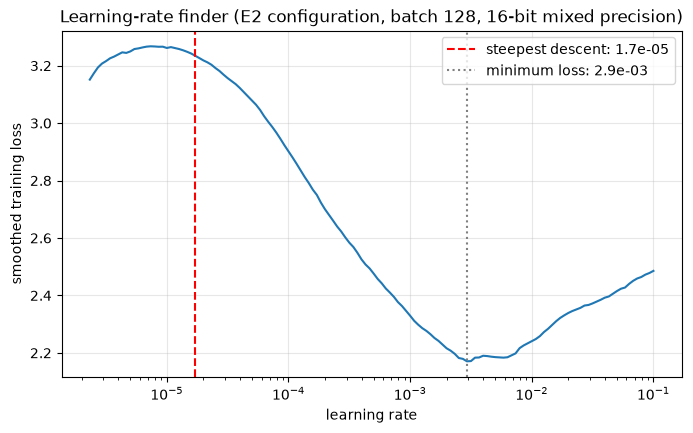

steps run: 150 | suggested lr (steepest descent): 1.71e-05 | lr at minimum loss: 2.93e-03


In [16]:
from pytorch_lightning.tuner import Tuner

pl.seed_everything(SEED, workers=True)
lr_dm = OEMDataModule(data_dir=OEM_ROOT, train_batch_size=128, num_workers=NUM_WORKERS, augment=True, train_repeats=4)
lr_model = OEMSegmentationModule(model=build_model("mit_b0"), lr=1e-4, loss="ce_dice", class_weights=CLASS_WEIGHTS)
# max_epochs must allow num_training steps (one epoch here is only ~58 steps)
lr_trainer = pl.Trainer(accelerator="auto", devices=1, precision="16-mixed", max_epochs=5,
                        logger=False, enable_checkpointing=False, enable_progress_bar=False)
lr_finder = Tuner(lr_trainer).lr_find(lr_model, datamodule=lr_dm, min_lr=1e-6, max_lr=1e-1, num_training=150)

# The first points of the smoothed loss are biased by the exponential moving average: skip them
SKIP = 10
lrs, losses = np.array(lr_finder.results["lr"]), np.array(lr_finder.results["loss"])
suggested_lr = lr_finder.suggestion(skip_begin=SKIP)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lrs[SKIP:], losses[SKIP:])
ax.axvline(suggested_lr, color="red", linestyle="--", label=f"steepest descent: {suggested_lr:.1e}")
ax.axvline(lrs[SKIP + np.argmin(losses[SKIP:])], color="gray", linestyle=":", label=f"minimum loss: {lrs[SKIP + np.argmin(losses[SKIP:])]:.1e}")
ax.set_xscale("log")
ax.set_xlabel("learning rate")
ax.set_ylabel("smoothed training loss")
ax.set_title("Learning-rate finder (E2 configuration, batch 128, 16-bit mixed precision)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(f"steps run: {len(lrs)} | suggested lr (steepest descent): {suggested_lr:.2e} | "
      f"lr at minimum loss: {lrs[SKIP + np.argmin(losses[SKIP:])]:.2e}")

**Choice of the learning rate.** The smoothed loss decreases steadily from about 1e-5 to a **minimum near 3e-3**, and rises beyond it as training becomes unstable. Lightning's automatic suggestion (the steepest point of the curve) falls at the very start of the descent, where the curve still reflects the smoothing warm-up rather than the learning rate, so we do not use it. Following the usual rule of thumb, roughly one order of magnitude below the minimum and well inside the descending region, we use **lr = 5e-4**, 5× the baseline learning rate. A higher learning rate is riskier for pretrained weights, so E3 pairs it with a 5% linear warm-up and a cosine decay.

In [17]:
E3_LR = 5e-4   # one order of magnitude below the minimum of the LR-finder curve (see above)

RESULTS["E3"] = run_experiment(
    "E3_lr_schedule_longer",
    f"E2 + lr {E3_LR:.0e} with warm-up + cosine decay, 3600 steps",
    augment=True,
    loss="ce_dice",
    class_weights=CLASS_WEIGHTS,
    lr=E3_LR,
    scheduler="cosine",
    max_epochs=60,
    patience=60,   # the cosine schedule needs the full budget; the best checkpoint is still selected by val_iou
)

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples



  | Name         | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------
0 | model        | Segformer                 | 3.7 M  | train | 0    
1 | ce_loss      | CrossEntropyLoss          | 0      | train | 0    
2 | dice_loss    | DiceLoss                  | 0      | train | 0    
3 | val_iou      | MulticlassJaccardIndex    | 0      | train | 0    
4 | test_iou     | MulticlassJaccardIndex    | 0      | train | 0    
5 | test_confmat | MulticlassConfusionMatrix | 0      | train | 0    
---------------------------------------------------------------------------
3.7 M     Trainable params
0         Non-trainable params
3.7 M     Total params
14.866    Total estimated model params size (MB)
198       Modules in train mode
0         Modules in eval mode
0         Total Flops


epoch   0 | step    58 | train_loss 2.3736 | val_loss 1.5511 | val_iou 0.4949 | lr 1.70e-04


...

epoch  58 | step  3422 | train_loss 0.7793 | val_loss 0.9864 | val_iou 0.6518 | lr 3.80e-07


epoch  59 | step  3480 | train_loss 0.7773 | val_loss 0.9862 | val_iou 0.6517 | lr 0.00e+00


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[test] Found 384 image/label pairs.


[E3_lr_schedule_longer] test mIoU (9 classes) = 0.6604 | test mIoU (8, no background) = 0.6223 | best epoch 53 | 44.6 min


In [18]:
RESULTS["E4"] = run_experiment(
    "E4_mit_b2",
    "E3 + mit_b2 encoder (batch 64 x 2 accumulation)",
    encoder="mit_b2",
    augment=True,
    loss="ce_dice",
    class_weights=CLASS_WEIGHTS,
    lr=E3_LR,
    scheduler="cosine",
    max_epochs=60,
    patience=60,
    train_batch_size=64,
    accumulate_grad_batches=2,
)

Seed set to 42


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[train] Found 2303 image/label pairs.
[train] Found 2303 image/label pairs.
Train: 1843 samples, Val: 460 samples



  | Name         | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------
0 | model        | Segformer                 | 24.7 M | train | 0    
1 | ce_loss      | CrossEntropyLoss          | 0      | train | 0    
2 | dice_loss    | DiceLoss                  | 0      | train | 0    
3 | val_iou      | MulticlassJaccardIndex    | 0      | train | 0    
4 | test_iou     | MulticlassJaccardIndex    | 0      | train | 0    
5 | test_confmat | MulticlassConfusionMatrix | 0      | train | 0    
---------------------------------------------------------------------------
24.7 M    Trainable params
0         Non-trainable params
24.7 M    Total params
98.898    Total estimated model params size (MB)
350       Modules in train mode
0         Modules in eval mode
0         Total Flops


epoch   0 | step    58 | train_loss 2.3835 | val_loss 1.4620 | val_iou 0.5018 | lr 1.70e-04


...

epoch  58 | step  3422 | train_loss 0.6603 | val_loss 0.9490 | val_iou 0.6793 | lr 3.80e-07


epoch  59 | step  3480 | train_loss 0.6585 | val_loss 0.9472 | val_iou 0.6797 | lr 0.00e+00


[test] Found 384 image/label pairs.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[E4_mit_b2] test mIoU (9 classes) = 0.6877 | test mIoU (8, no background) = 0.6528 | best epoch 43 | 77.7 min


## Results

### Learning curves

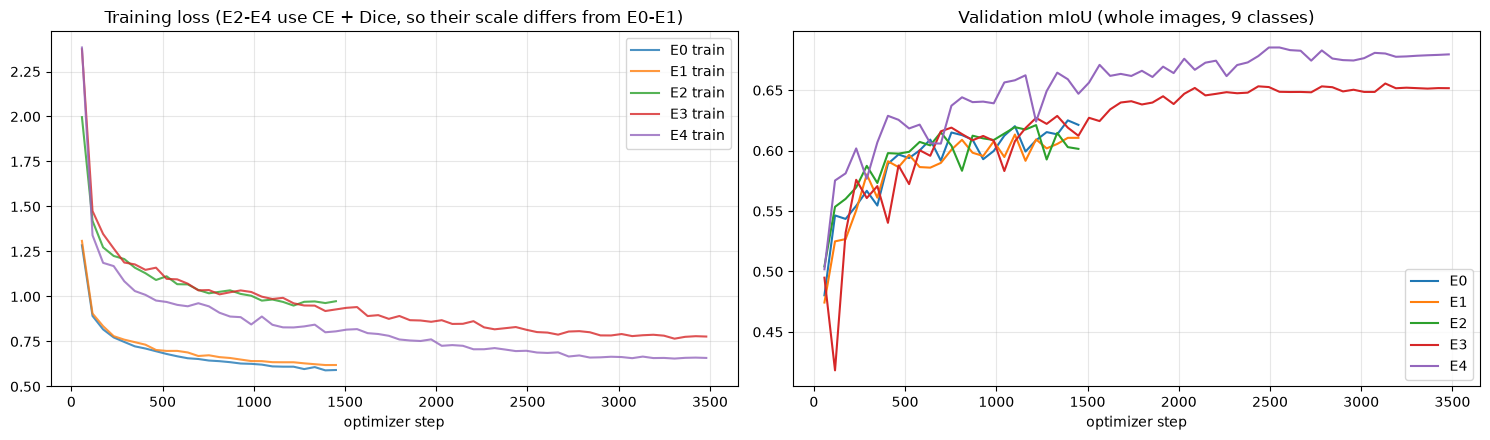

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for key, res in RESULTS.items():
    steps = [h["step"] for h in res["history"]]
    axes[0].plot(steps, [h["train_loss"] for h in res["history"]], label=f"{key} train", alpha=0.8)
    axes[1].plot(steps, [h["val_iou"] for h in res["history"]], label=key)
axes[0].set_title("Training loss (E2-E4 use CE + Dice, so their scale differs from E0-E1)")
axes[1].set_title("Validation mIoU (whole images, 9 classes)")
for ax in axes:
    ax.set_xlabel("optimizer step")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Comparison table

In [20]:
import pandas as pd

table = pd.DataFrame([
    {
        "run": key,
        "change": res["description"],
        "steps": res["history"][-1]["step"],
        "best epoch": res["best_epoch"],
        "val mIoU": res["best_val_iou"],
        "test mIoU (9 cls)": res["test_iou"],
        "test mIoU (8 cls, no bg)": res["test_miou_8_no_background"],
        "train time (min)": res["train_minutes"],
    }
    for key, res in RESULTS.items()
]).set_index("run")
table["Δ test mIoU vs E0"] = table["test mIoU (9 cls)"] - table.loc["E0", "test mIoU (9 cls)"]
pd.set_option("display.max_colwidth", 80)
table.round(4)

,change,steps,best epoch,val mIoU,test mIoU (9 cls),"test mIoU (8 cls, no bg)",train time (min),Δ test mIoU vs E0
run,,,,,,,,
E0,"Baseline (TODO spec): mit_b0, CE, no augmentation, lr 1e-4 constant",1450,23,0.6251,0.6283,0.5879,17.2647,0.0000
E1,"E0 + augmentation (flips, rot90, colour jitter)",1450,18,0.6134,0.6246,0.5860,17.7145,-0.0038
E2,E1 + class-weighted CE + Dice loss,1450,20,0.6212,0.6174,0.5744,19.4792,-0.0110
E3,"E2 + lr 5e-04 with warm-up + cosine decay, 3600 steps",3480,53,0.6556,0.6604,0.6223,44.6156,0.0321
E4,E3 + mit_b2 encoder (batch 64 x 2 accumulation),3480,43,0.6854,0.6877,0.6528,77.6903,0.0593


### Per-class IoU on the test set

,E0,E1,E2,E3,E4,pixel share % (test)
Background,0.952,0.933,0.961,0.965,0.966,0.842
Bareland,0.413,0.379,0.394,0.449,0.495,1.280
Rangeland,0.527,0.519,0.506,0.531,0.552,20.877
Developed space,0.509,0.485,0.480,0.521,0.559,19.642
Road,0.514,0.520,0.521,0.574,0.615,7.004
Tree,0.634,0.668,0.650,0.684,0.705,18.631
Water,0.683,0.690,0.658,0.731,0.769,2.341
Agriculture land,0.711,0.714,0.682,0.749,0.757,11.726
Building,0.712,0.713,0.705,0.739,0.772,17.657


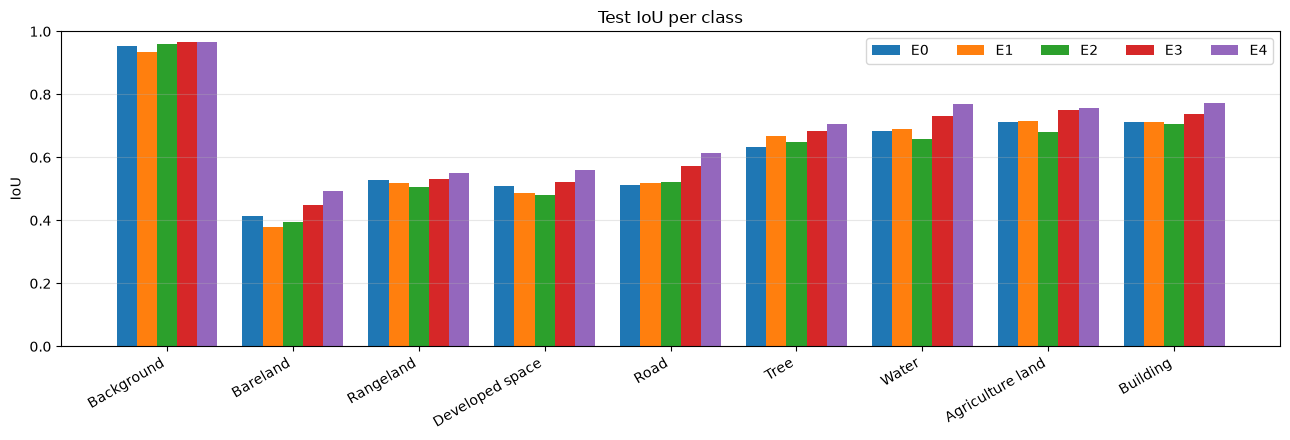

In [21]:
per_class = pd.DataFrame({key: res["per_class_iou"] for key, res in RESULTS.items()}, index=CLASS_NAMES)
per_class["pixel share % (test)"] = 100 * freq["test"]
display(per_class.round(3))

keys = list(RESULTS)
fig, ax = plt.subplots(figsize=(13, 4.5))
width = 0.8 / len(keys)
for i, key in enumerate(keys):
    ax.bar(np.arange(9) + (i - (len(keys) - 1) / 2) * width, per_class[key], width=width, label=key)
ax.set_xticks(np.arange(9), CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("IoU")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=len(keys))
ax.set_title("Test IoU per class")
plt.tight_layout()
plt.show()

### Confusion matrix of the best model

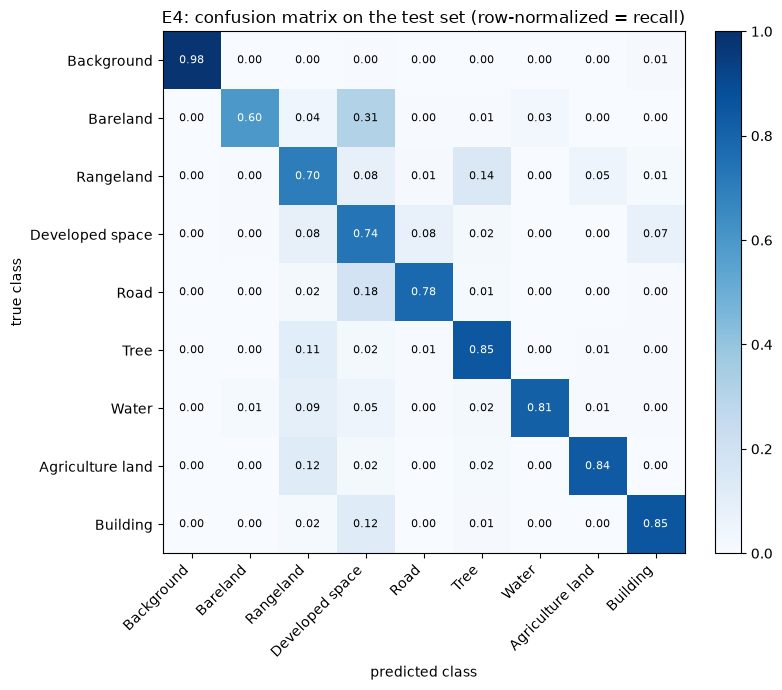

 31.4% of Bareland pixels predicted as Developed space
 18.2% of Road pixels predicted as Developed space
 14.1% of Rangeland pixels predicted as Tree
 12.0% of Agriculture land pixels predicted as Rangeland
 11.8% of Building pixels predicted as Developed space
 10.9% of Tree pixels predicted as Rangeland


In [22]:
BEST = max(RESULTS, key=lambda k: RESULTS[k]["test_iou"])
confusion = np.array(RESULTS[BEST]["confusion"], dtype=np.float64)
recall_matrix = confusion / np.maximum(confusion.sum(axis=1, keepdims=True), 1)   # rows: true class

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(recall_matrix, cmap="Blues", vmin=0, vmax=1)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{recall_matrix[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if recall_matrix[i, j] > 0.5 else "black")
ax.set_xticks(range(9), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(9), CLASS_NAMES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title(f"{BEST}: confusion matrix on the test set (row-normalized = recall)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# The largest off-diagonal entries: which classes get confused with which
off_diagonal = [(recall_matrix[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(9) for j in range(9) if i != j]
for share, true_name, pred_name in sorted(off_diagonal, reverse=True)[:6]:
    print(f"{100 * share:5.1f}% of {true_name} pixels predicted as {pred_name}")

### Qualitative results on test images

[test] Found 384 image/label pairs.


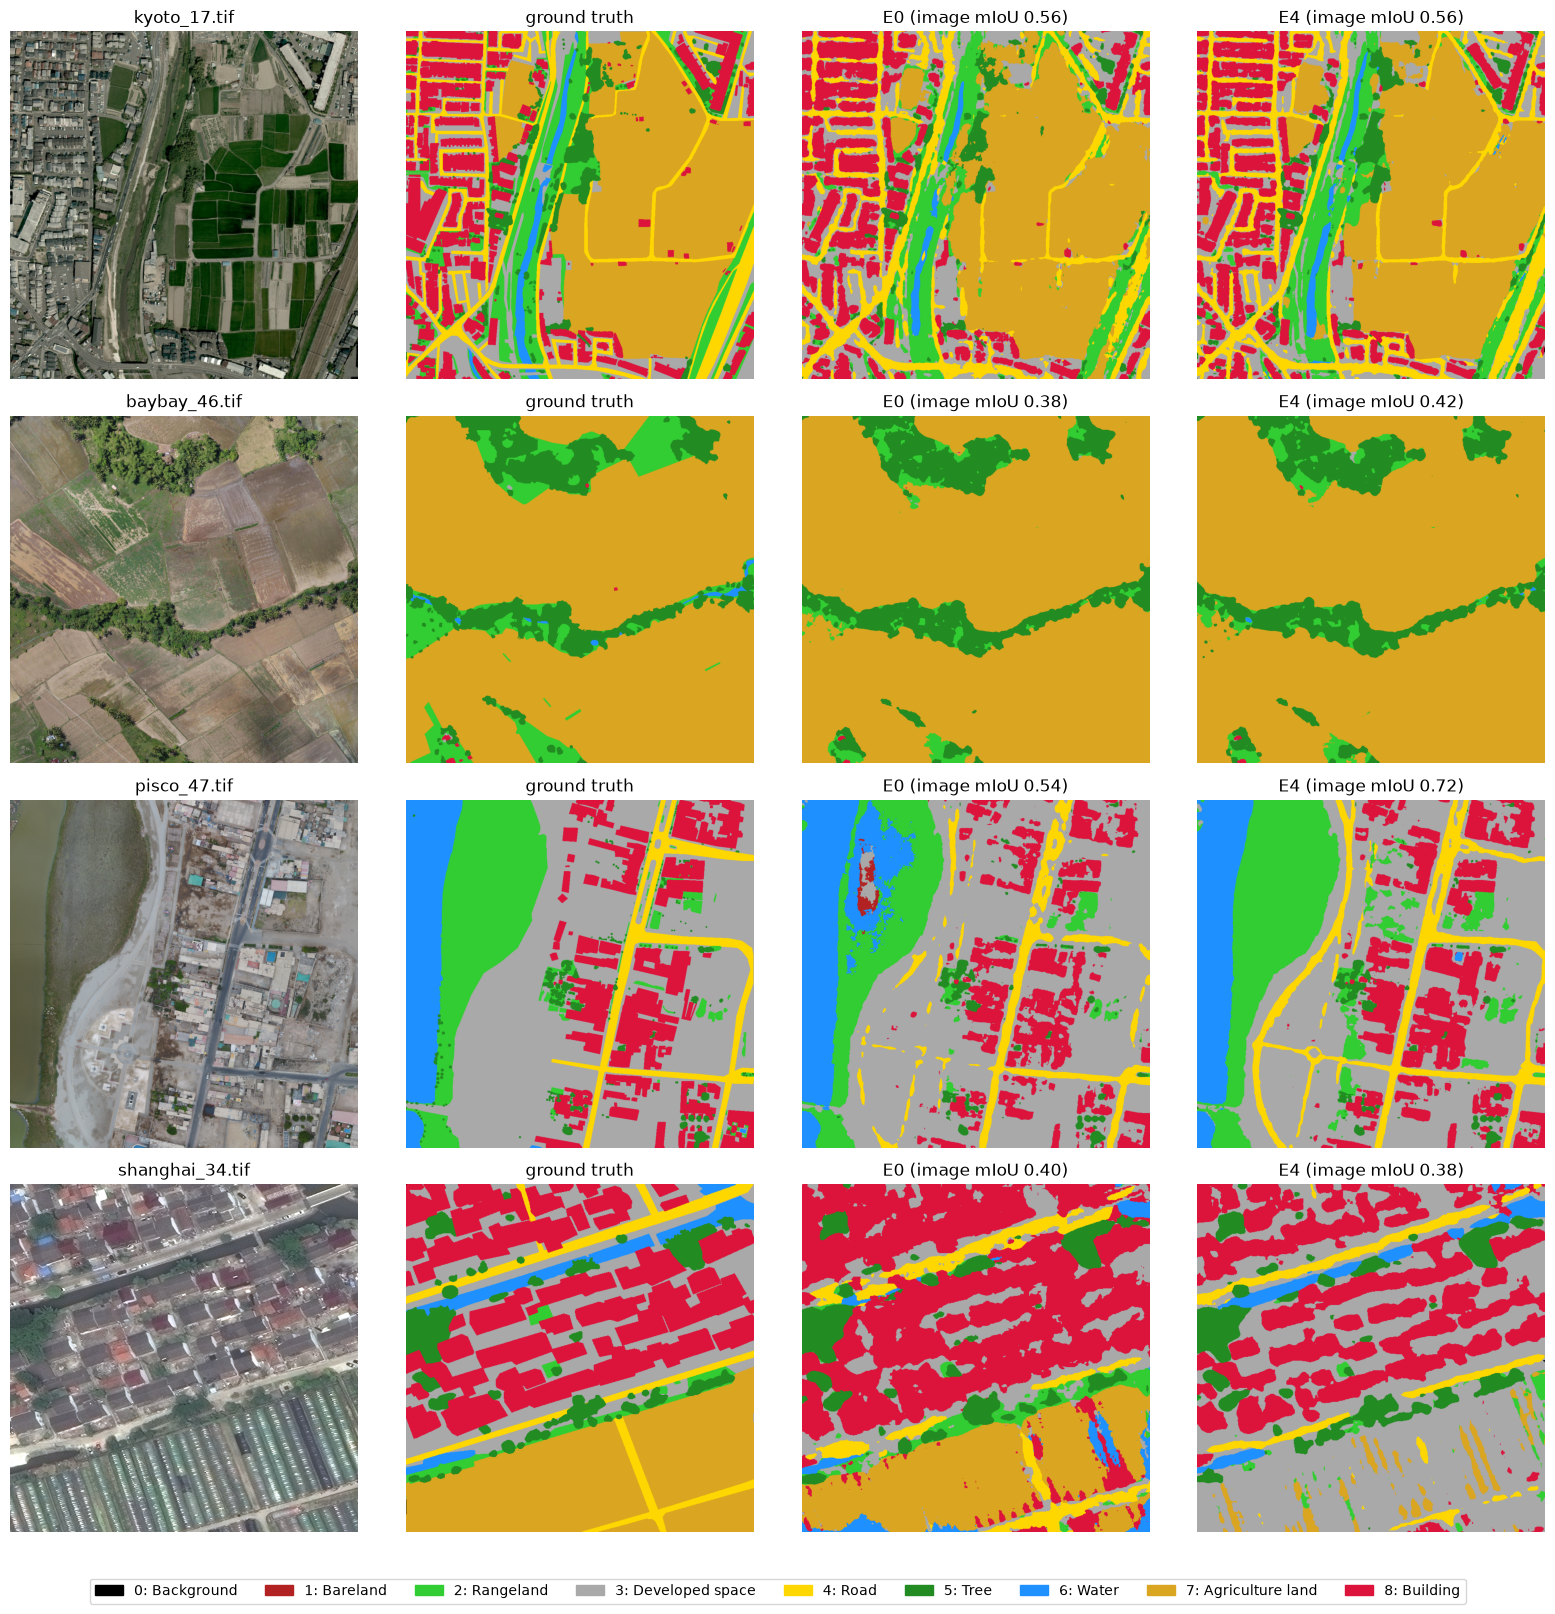

In [23]:
def load_best(key):
    res = RESULTS[key]
    module = OEMSegmentationModule.load_from_checkpoint(
        res["best_checkpoint"], model=build_model(res["config"]["encoder"], pretrained=False)
    )
    return module.eval().to("cuda" if torch.cuda.is_available() else "cpu")


qual_dm = OEMDataModule(data_dir=OEM_ROOT, num_workers=0)
qual_dm.setup("test")
test_ds = qual_dm.test_dataset
models_to_show = {"E0": load_best("E0"), BEST: load_best(BEST)}

rng = np.random.default_rng(SEED)
indices = rng.choice(len(test_ds), size=4, replace=False)
fig, axes = plt.subplots(len(indices), 2 + len(models_to_show), figsize=(4 * (2 + len(models_to_show)), 4 * len(indices)))
for row, idx in enumerate(indices):
    image, label = test_ds[idx]
    valid = (label != IGNORE_INDEX).numpy()
    h, w = valid.any(axis=1).sum(), valid.any(axis=0).sum()
    panels = [denormalize(image)[:h, :w], colorize(label.numpy())[:h, :w]]
    titles = [os.path.basename(test_ds.input_paths[idx]), "ground truth"]
    for key, module in models_to_show.items():
        with torch.no_grad(), torch.autocast(module.device.type, dtype=torch.float16, enabled=module.device.type == "cuda"):
            pred = module(image.unsqueeze(0).to(module.device)).argmax(1)[0].cpu().numpy()
        # IoU of this single image, over the classes present in its ground truth or prediction
        conf = np.bincount(9 * label.numpy()[valid] + pred[valid], minlength=81).reshape(9, 9)
        present = (conf.sum(0) + conf.sum(1)) > 0
        panels.append(colorize(pred)[:h, :w])
        titles.append(f"{key} (image mIoU {iou_from_confusion(conf)[present].mean():.2f})")
    for col, (panel, title) in enumerate(zip(panels, titles)):
        axes[row, col].imshow(panel)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
legend_patches = [mpatches.Patch(color=CLASS_COLORS[k] / 255.0, label=f"{k}: {CLASS_NAMES[k]}") for k in range(9)]
fig.legend(handles=legend_patches, loc="lower center", ncol=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Discussion

**Main result.** The best model, E4 (SegFormer `mit_b2`), reaches a test mIoU of **0.688** over the 9 classes and **0.653** over the 8 land-cover classes, against 0.628 / 0.588 for the baseline (**+0.059 / +0.065**). In every run the best validation mIoU and the test mIoU differ by at most 0.012. The validation split, drawn from the same regions as the test set, is therefore a reliable proxy for model selection.

**What helped.**
- **Training budget and learning-rate schedule (E2 → E3: +0.043; +0.032 over the baseline).** The validation curves of E0–E2 are still rising when training stops at ~1,450 steps, and their best checkpoints come from the last epochs (epochs 18–23 of 25). With a learning rate 5× higher (chosen with the LR finder), a warm-up, a cosine decay and 3,480 steps, the model converges: the E3 curve flattens in the second half of the schedule.
- **Model capacity (E3 → E4: +0.027).** `mit_b2` improves every class. The largest gains are on Bareland (+0.045), Road (+0.041), Developed space (+0.038), Water (+0.037) and Building (+0.033), the classes that need finer boundaries or more context. The cost is 1.7× the training time (78 vs 45 minutes).

**What did not help at the baseline budget.** Augmentation (E1: −0.004) and the class-weighted CE + Dice loss (E2: −0.007 vs. E1) leave the test mIoU within ±0.011 of the baseline. The class weights did not even raise the rare classes at this budget: Bareland went from 0.379 to 0.394, while Water fell from 0.690 to 0.658. Two factors explain this:
1. **The model is under-fitting.** The training loss is still decreasing at step 1,450, and augmentation and Dice act as regularizers that make the objective harder, so they cannot pay off yet.
2. **Each configuration was trained once**, and the epoch-to-epoch oscillation of the validation mIoU (about ±0.02) is larger than these differences.

Augmentation and the CE + Dice loss are kept in E3 and E4, but we did not run the control "long training without them". Their contribution at the longer budget is therefore not isolated.

**Error analysis.**
- **Background is the easiest class (IoU 0.97)** even though it covers only 0.8% of the pixels: unlabelled areas are visually distinctive. Water (2.3% of the pixels) reaches 0.77. Rarity alone does not make a class hard; ambiguity does.
- **The hardest classes are Bareland (0.49), Rangeland (0.55) and Developed space (0.56).** The confusion matrix shows why: 31% of Bareland pixels are predicted as Developed space, 18% of Road pixels as Developed space, and Rangeland and Tree are confused in both directions (14% and 11%). These pairs look alike from above (bare soil vs. unpaved open space, grass vs. scrub and tree canopy), and the boundary between them depends on context and on annotation conventions.
- **Qualitative examples.** On `pisco_47` the baseline predicts patches of Bareland and Building inside a water body, which E4 labels correctly (image mIoU 0.54 → 0.72). On `shanghai_34` both models label greenhouses, annotated as Agriculture land, as Developed space or Building: an appearance that is rare in the training set and resembles built structures.

## Conclusions and limitations

The baseline required by the TODOs (0.628 test mIoU) was mainly limited by its training budget. A learning rate selected with the LR finder, a warm-up + cosine schedule and a 2.4× longer training raise it to 0.660, and a larger encoder to **0.688**. The remaining errors are concentrated on semantically adjacent classes rather than on rare ones.

Limitations of this study:
- **One seed per configuration**: differences below ~0.02 mIoU should not be considered significant.
- **The ablation is cumulative, and E3 changes the learning rate, the schedule and the budget together.** Their individual effects, and the effect of augmentation and of the loss at the longer budget, are not separated.
- **Train/test scale mismatch**: the model is trained on 224×224 crops and evaluated on whole images of up to 1024×1024. Larger training crops would give more context, but `mit_b2` at 512×512 with batch 32 does not fit in 16 GB of GPU memory.
- **In-distribution evaluation**: validation and test come from the same 75 regions, so the scores do not measure generalization to unseen cities.

Natural next steps: repeated runs with different seeds, a region-held-out evaluation, test-time augmentation (flips), and larger crops with gradient accumulation.

## Execution environment

The outputs in this notebook were produced on a local workstation (NVIDIA RTX 3080 Laptop GPU, 16 GB) with Python 3.12 and the package versions listed in `pyproject.toml` / `uv.lock`. The notebook is also set up for Google Colab with a T4 GPU (16 GB): the first cell detects the environment and stores the dataset under `/content`, as in the original setup. Only the local execution was actually tested. On Colab, with 2 CPU cores, data loading is slower, so the full ablation study takes longer. Thanks to the result cache, a restarted session resumes from the first experiment that is not finished.

In [24]:
import platform
import albumentations, segmentation_models_pytorch, torchmetrics

print("python", platform.python_version(), "| torch", torch.__version__, "| lightning", pl.__version__,
      "| smp", segmentation_models_pytorch.__version__, "| torchmetrics", torchmetrics.__version__,
      "| albumentations", albumentations.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

python 3.12.3 | torch 2.14.1+cu130 | lightning 2.6.6 | smp 0.5.0 | torchmetrics 1.9.0 | albumentations 2.0.8
GPU: NVIDIA GeForce RTX 3080 Laptop GPU
